In [1]:
import pypsa
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

from synthseer import *
%load_ext autoreload
%autoreload 2

In [2]:
input_data = synth_data(2025, nyears=3, load_growth=2, excess_cap=1)

In [3]:
model = create_model_from_data(input_data)

In [8]:
minpu, maxpu = model.components.Generator.get_bounds_pu()

In [10]:
model.generators

,bus,control,type,p_nom,p_nom_mod,p_nom_extendable,p_nom_min,p_nom_max,p_nom_set,p_min_pu,...,min_up_time,min_down_time,up_time_before,down_time_before,ramp_limit_up,ramp_limit_down,ramp_limit_start_up,ramp_limit_shut_down,weight,p_nom_opt
name,,,,,,,,,,,,,,,,,,,,,
gas - 0_exist,0,Slack,,68.493151,0.0,False,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,68.493151
gas - 0_2025,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,8846.304625
gas - 0_2026,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,-0.000000
gas - 0_2027,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,-0.000000
wind - 0_exist,0,PQ,,154.109589,0.0,False,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,154.109589
wind - 0_2025,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,5243.944632
wind - 0_2026,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,12930.568027
wind - 0_2027,0,PQ,,0.000000,0.0,True,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,-0.000000
solar - 0_exist,0,PQ,,102.739726,0.0,False,0.0,inf,NaN,0.0,...,0,0,1,0,NaN,NaN,1.0,1.0,1.0,102.739726


In [17]:
model.components.Load

'Load' Components
-----------------
Attached to PyPSA Network 'Unnamed Network'
Components: 1

In [6]:
model.optimize()

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████████| 2/2 [00:00<00:00,  2.87it/s]
INFO:linopy.io: Writing time: 5.6s


Running HiGHS 1.12.0 (git hash: n/a): Copyright (c) 2025 HiGHS under MIT licence terms
LP linopy-problem-7ot8yb9k has 867255 rows; 420495 cols; 1498515 nonzeros
Coefficient ranges:
  Matrix  [2e-04, 1e+00]
  Cost    [5e+00, 5e+05]
  Bound   [0e+00, 0e+00]
  RHS     [3e-02, 2e+04]
Presolving model
256650 rows, 368505 cols, 829230 nonzeros  1s
Dependent equations search running on 26280 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.01s (limit = 1000.00s)
256650 rows, 355095 cols, 815820 nonzeros  2s
Presolve reductions: rows 256650(-610605); columns 355095(-65400); nonzeros 815820(-682695) 
Solving the presolved LP
Using EKK dual simplex solver - serial
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 26280(5.37312e+07) 3s
      96903     6.5883058048e+09 Pr: 19432(1.5171e+07); Du: 0(1.23515e-07) 8s
     105729     6.9074486443e+09 Pr: 37348(4.49526e+08); Du: 0(1.63981e-07) 14s
     111643

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 420495 primals, 867255 duals
Objective: 7.34e+09
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-ext-p-lower, Generator-ext-p-upper were not assigned to the network.


('ok', 'optimal')

/Users/mohini/Documents/repos/rhiza/seer/synthseer.py:288: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



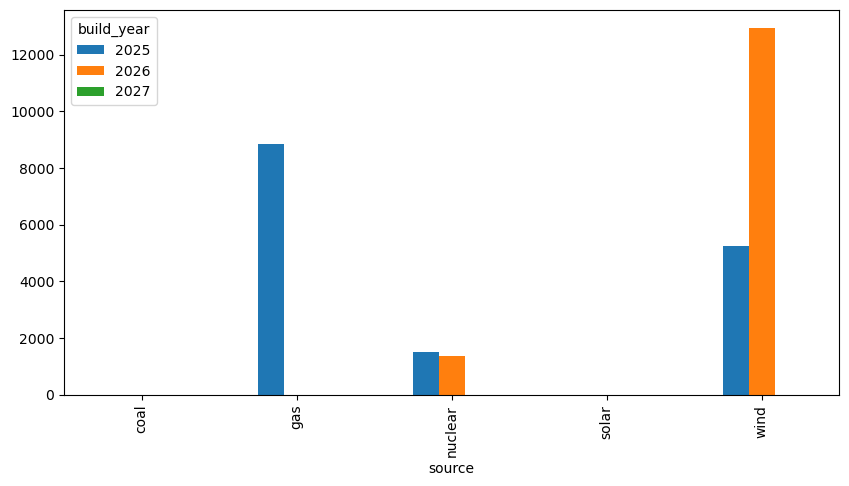

In [12]:
viz_model(model)

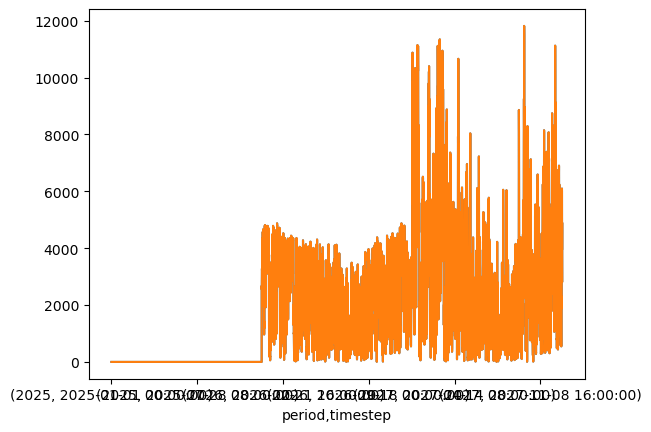

In [22]:
model.generators_t.p["wind - 0_2026"].plot()
plt.show()